# Implied Volatility Smile & Surface

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Implied volatility (the σ that makes Black–Scholes match an option's market price) plotted across strikes for several expiries (the smile or skew), next to a strike × expiry heatmap of the whole surface. It shows how the market prices tail risk and how that changes with time.

## When to use

- Show equity skew: downside puts priced at higher volatility than upside calls
- Compare smile steepness across expiries (short-dated skew is usually steeper)
- Quality-check a volatility surface before using it for pricing or risk

## Avoid when

- Audiences without options background (explain implied volatility first, or show a single ATM term structure)
- 3-D surface plots for reports (hard to read exact values; occlusion); use lines plus a heatmap

## Alternatives

- ATM volatility term structure line
- 25-delta risk-reversal time series

## Design tips

- Order expiry colors with a one-hue ramp (light = near, dark = far), since expiry is ordered
- Mark the spot or forward price on the strike axis
- Annotate heatmap cells only if the grid is small; otherwise rely on the colorbar

## Example

A parametric equity-style surface: ATM vol rising with maturity, skew and curvature fading as 1/√T (simulated, spot $100).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
S0, r = 100.0, 0.04
expiries = {"1M": 1 / 12, "3M": 0.25, "6M": 0.5, "1Y": 1.0, "2Y": 2.0}
strikes = np.arange(70, 131, 5)


def implied_vol(K, T):
    k = np.log(K / (S0 * np.exp(r * T)))             # log-moneyness vs forward
    atm = 0.16 + 0.04 * (1 - np.exp(-T))
    skew = -0.12 / np.sqrt(T)
    curvature = 0.25 / np.sqrt(T)
    return np.maximum(atm + skew * k + curvature * k ** 2, 0.05)


iv = pd.DataFrame({name: implied_vol(strikes, T) * 100 for name, T in expiries.items()},
                  index=pd.Index(strikes, name="strike")).round(1)
iv.T

strike,70,75,80,85,90,95,100,105,110,115,120,125,130
1M,42.5,35.8,30.2,25.6,21.9,18.8,16.5,14.6,13.2,12.3,11.7,11.4,11.4
3M,32.4,28.5,25.2,22.5,20.3,18.5,17.1,16.0,15.2,14.6,14.2,14.0,14.0
6M,29.0,26.1,23.8,21.8,20.3,19.0,17.9,17.1,16.5,16.0,15.8,15.6,15.5
1Y,27.2,25.1,23.4,22.0,20.8,19.8,19.0,18.4,17.9,17.6,17.3,17.2,17.1
2Y,26.5,25.0,23.7,22.6,21.6,20.9,20.3,19.7,19.3,19.0,18.8,18.6,18.5


### Plot

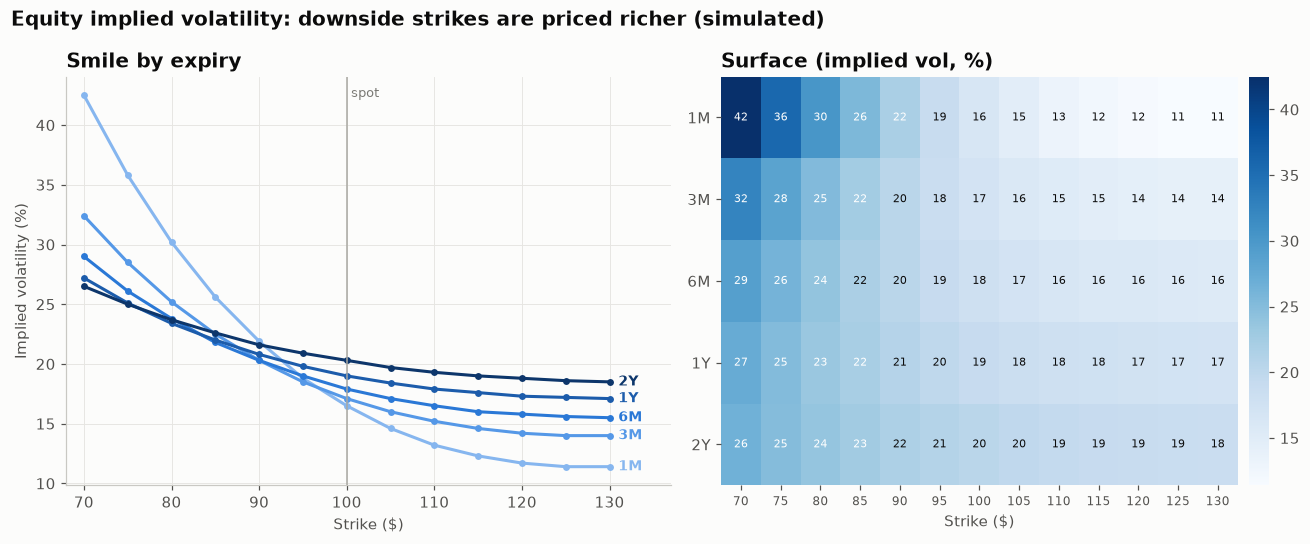

In [3]:
ramp = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]   # ordinal: near -> far
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.1, 1]})
for (name, col), color in zip(iv.items(), ramp):
    ax1.plot(iv.index, col, color=color, linewidth=2, marker="o", markersize=3.5)
    ax1.text(iv.index[-1] + 1, col.iloc[-1], name, color=color, va="center", fontsize=9, fontweight="bold")
ax1.axvline(S0, color="#a9a8a2", linewidth=1)
ax1.text(S0 + 0.5, ax1.get_ylim()[1] * 0.98, "spot", color="#7a7974", fontsize=8.5, va="top")
ax1.set_xlim(iv.index[0] - 2, iv.index[-1] + 7)
ax1.set_xlabel("Strike ($)")
ax1.set_ylabel("Implied volatility (%)")
ax1.set_title("Smile by expiry")

z = iv.T.to_numpy()
im = ax2.imshow(z, cmap=SEQ_CMAP, aspect="auto", origin="upper")
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax2.text(j, i, f"{z[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                 color="white" if z[i, j] > np.percentile(z, 70) else "#0b0b0b")
ax2.set_xticks(range(len(strikes)), strikes, fontsize=8)
ax2.set_yticks(range(len(expiries)), list(expiries))
ax2.set_xlabel("Strike ($)")
ax2.set_title("Surface (implied vol, %)")
ax2.grid(False)
for sp in ax2.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax2, fraction=0.04, pad=0.02)
cb.outline.set_visible(False)
fig.suptitle("Equity implied volatility: downside strikes are priced richer (simulated)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Every curve slopes down to the right, so low strikes (crash protection) carry higher implied vol. The 1-month curve (lightest) is the steepest. In the heatmap the darkest cells sit at low strikes and short expiries.

---
Standalone script: [`volatility_smile_surface.py`](volatility_smile_surface.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)